# Real-source and annotation analysis
Executed from the frozen DiDeMo v2 staging manifest and train/validation annotations. No raw descriptions, videos or test targets are displayed.

In [1]:
from pathlib import Path
import json,hashlib,collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'src').exists()
import os
os.chdir(ROOT)
def read(path):return json.loads(Path(path).read_text(encoding='utf-8'))
def table(rows,title):
    if not rows:return
    columns=list(rows[0]);html='<h4>'+title+'</h4><table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'
    for row in rows:html+='<tr>'+''.join('<td>'+str(row[c])+'</td>' for c in columns)+'</tr>'
    display(HTML(html+'</table>'))
def save_plot(name):
    plt.tight_layout();Path('docs/figures').mkdir(exist_ok=True)
    plt.savefig('docs/figures/'+name+'.png',dpi=150)
    plt.show()
SOURCE=Path('data/processed/didemo-v2')
CACHE=Path('data/interim/cloud-smoke-output-v1/video-smoke')
RUN_ENCODER=False
RUN_TRAINING=False
RUN_TEST=False


split,source_video_ids,unique_media,queries,test_targets_staged
train,364,364,1390,False
val,74,73,261,False
test,47,47,None,False


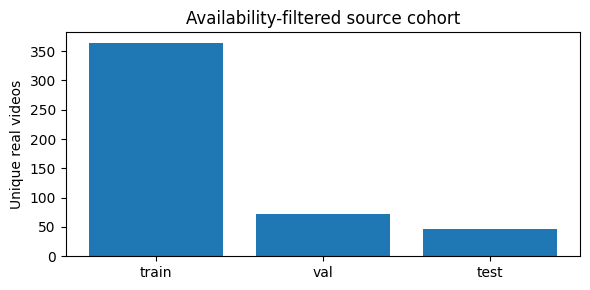

In [2]:
manifest=read(SOURCE/'manifest.json');media=read(SOURCE/'media.json')
queries={s:read(SOURCE/(s+'.json')) for s in ('train','val')}
table([{'split':s,**r} for s,r in manifest['counts'].items()],'Available cohort after geometry audit')
plt.figure(figsize=(6,3));splits=['train','val','test'];plt.bar(splits,[sum(r['split']==s for r in media) for s in splits]);plt.ylabel('Unique real videos');plt.title('Availability-filtered source cohort');save_plot('source-split-counts')


In [3]:
"""Temporal retrieval metrics for inclusive DiDeMo five-second bin intervals.

Corpus consensus recall is a custom metric. Official within-video metrics follow
LisaAnne/LocalizingMoments utils/eval.py at the pinned data revision.
"""

import numpy as np

def interval(value):
    if not isinstance(value, (list, tuple)) or len(value) != 2:
        raise ValueError('Expected inclusive start/end bins')
    a,b=value
    if type(a) is not int or type(b) is not int or not 0 <= a <= b < 6:
        raise ValueError('Invalid DiDeMo bin interval')
    return a,b

def moments(num_segments):
    if type(num_segments) is not int or not 1 <= num_segments <= 6:
        raise ValueError('Expected one through six segments')
    return [(a,b) for a in range(num_segments) for b in range(a,num_segments)]

def iou(prediction, reference):
    a,b=interval(prediction);c,d=interval(reference)
    return max(0,min(b,d)+1-max(a,c))/(max(b,d)+1-min(a,c))

def consensus_iou(prediction, references):
    if not references:raise ValueError('Missing human temporal references')
    values=sorted(iou(prediction,ref) for ref in references)
    return float(np.mean(values[-3:]))

def positive_mask(candidates, query):
    return np.asarray([c['video']==query['video'] and
        consensus_iou(c['moment'],query['times']) >= .5 for c in candidates],dtype=bool)

def evaluate(scores, candidates, queries):
    scores=np.asarray(scores)
    if scores.shape != (len(queries),len(candidates)) or not queries or not candidates:
        raise ValueError('Nonempty query by candidate score matrix required')
    if not np.isfinite(scores).all():raise ValueError('Nonfinite retrieval scores')
    keys=[(c['video'],interval(c['moment'])) for c in candidates]
    if len(set(keys))!=len(keys):raise ValueError('Duplicate candidate moments')
    corpus1=[];corpus5=[];video1=[];video5=[];local1=[];local5=[];local_iou=[];attainable=[]
    for row,q in zip(scores,queries):
        refs=[interval(t) for t in q['times']]
        if not refs:raise ValueError('Missing temporal references')
        order=np.argsort(-row,kind='stable')
        local=[i for i in order if candidates[i]['video']==q['video']]
        if not local:raise ValueError('Correct video absent from candidate corpus')
        local_moments=[keys[i][1] for i in local]
        if any(t not in local_moments for t in refs):
            raise ValueError('Human reference missing from candidate geometry')
        positives=positive_mask(candidates,q)
        corpus1.append(bool(positives[order[0]]));corpus5.append(bool(positives[order[:5]].any()))
        video1.append(candidates[order[0]]['video']==q['video'])
        video5.append(any(candidates[i]['video']==q['video'] for i in order[:5]))
        ranks=sorted(local_moments.index(t)+1 for t in refs)
        average_rank=float(np.mean(ranks[:3]))
        local1.append(average_rank <= 1);local5.append(average_rank <= 5)
        local_iou.append(consensus_iou(local_moments[0],refs));attainable.append(bool(positives.any()))
    mean=lambda x:float(np.mean(x))
    return {'queries':len(queries),'candidate_moments':len(candidates),
        'corpus_consensus_r1_iou50':mean(corpus1),'corpus_consensus_r5_iou50':mean(corpus5),
        'corpus_video_r1':mean(video1),'corpus_video_r5':mean(video5),
        'within_video_official_rank1':mean(local1),'within_video_official_rank5':mean(local5),
        'within_video_official_miou':mean(local_iou),
        'consensus_attainable_fraction':mean(attainable),
        'metric_scope':'licensed available subset; corpus metrics custom; within-video formula official',
        'tie_rule':'stable original candidate order; no gold-dependent tie breaking'}

## Description length and human disagreement
Reference disagreement is inherent in moment localization. Maximum possible consensus overlap is measured from candidate geometry; unattainable rows remain in evaluation denominators.

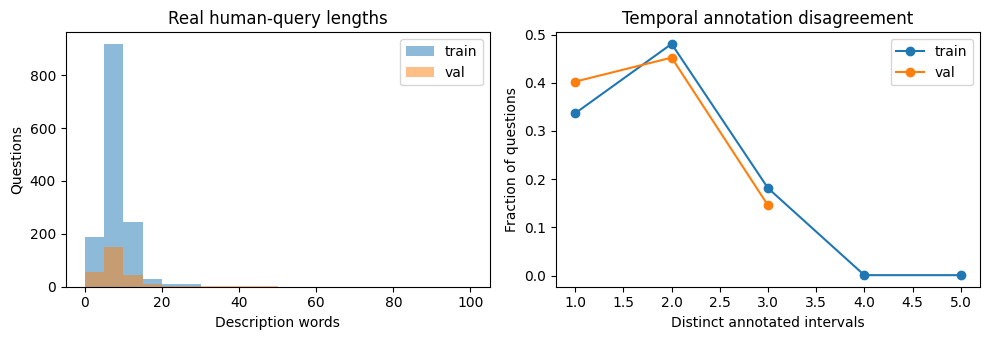

split,queries,multiple distinct references,no consensus-positive moment,mean attainable consensus IoU
train,1390,922,0,0.960468
val,261,156,0,0.962963


In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for split,rows in queries.items():
    axes[0].hist([len(r['text'].split()) for r in rows],bins=[0,5,10,15,20,30,50,100],alpha=.5,label=split)
    counts=collections.Counter(len({tuple(t) for t in r['times']}) for r in rows)
    axes[1].plot(sorted(counts),[counts[k]/len(rows) for k in sorted(counts)],marker='o',label=split)
axes[0].set(xlabel='Description words',ylabel='Questions',title='Real human-query lengths');axes[0].legend()
axes[1].set(xlabel='Distinct annotated intervals',ylabel='Fraction of questions',title='Temporal annotation disagreement');axes[1].legend();save_plot('annotation-distributions')
geometry={r['video']:r['num_segments'] for r in media}
summary=[]
for split,rows in queries.items():
    ceilings=[max(consensus_iou(m,row['times']) for m in moments(geometry[row['video']])) for row in rows]
    summary.append({'split':split,'queries':len(rows),'multiple distinct references':sum(len({tuple(t) for t in r['times']})>1 for r in rows),
        'no consensus-positive moment':sum(v<.5 for v in ceilings),'mean attainable consensus IoU':round(float(np.mean(ceilings)),6)})
table(summary,'Annotation/geometry attainable overlap; not model accuracy')


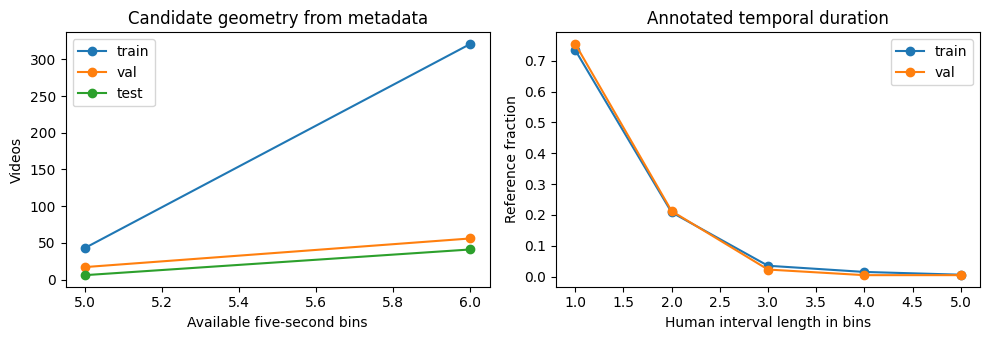

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for split in ('train','val','test'):
    counts=collections.Counter(r['num_segments'] for r in media if r['split']==split)
    axes[0].plot(sorted(counts),[counts[k] for k in sorted(counts)],marker='o',label=split)
for split,rows in queries.items():
    lengths=[t[1]-t[0]+1 for r in rows for t in r['times']]
    counts=collections.Counter(lengths);axes[1].plot(sorted(counts),[counts[k]/len(lengths) for k in sorted(counts)],marker='o',label=split)
axes[0].set(xlabel='Available five-second bins',ylabel='Videos',title='Candidate geometry from metadata');axes[0].legend()
axes[1].set(xlabel='Human interval length in bins',ylabel='Reference fraction',title='Annotated temporal duration');axes[1].legend();save_plot('temporal-geometry')


## Limits
These sources were available with acceptable licenses at preparation time; availability and source-owner correlation can bias the subset. Exact-media split isolation does not rule out near duplicates, common creators or CLIP pretraining overlap. Test geometry above uses media metadata only.